In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

In [2]:
data = {
    'Annual_Income': [15, 16, 17, 18, 19, 20,
                      40, 42, 43, 45, 47, 48,
                      70, 72, 73, 75, 77, 80],

    'Spending_Score': [80, 82, 78, 85, 79, 83,
                       40, 42, 38, 45, 41, 44,
                       20, 18, 25, 22, 24, 19]
}

df = pd.DataFrame(data)

df

,Annual_Income,Spending_Score
0,15,80
1,16,82
2,17,78
3,18,85
4,19,79
5,20,83
6,40,40
7,42,42
8,43,38
9,45,45


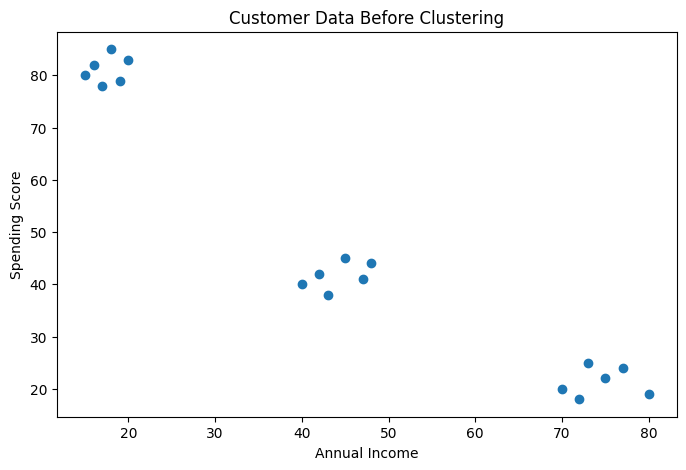

In [3]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df['Annual_Income'],
    df['Spending_Score']
)

plt.xlabel('Annual Income')
plt.ylabel('Spending Score')
plt.title('Customer Data Before Clustering')

plt.show()

In [4]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

df['Cluster'] = kmeans.fit_predict(
    df[['Annual_Income', 'Spending_Score']]
)

df

,Annual_Income,Spending_Score,Cluster
0,15,80,2
1,16,82,2
2,17,78,2
3,18,85,2
4,19,79,2
5,20,83,2
6,40,40,0
7,42,42,0
8,43,38,0
9,45,45,0


In [5]:
print("Cluster Centers:")

print(kmeans.cluster_centers_)

Cluster Centers:
[[44.16666667 41.66666667]
 [74.5        21.33333333]
 [17.5        81.16666667]]


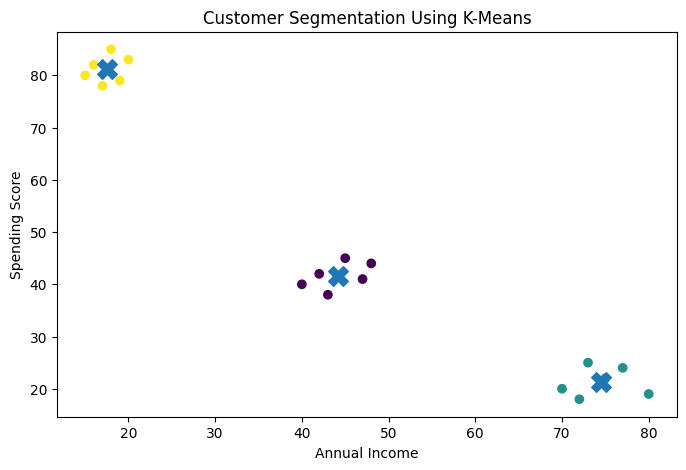

In [6]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df['Annual_Income'],
    df['Spending_Score'],
    c=df['Cluster']
)

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    marker='X',
    s=200
)

plt.xlabel('Annual Income')
plt.ylabel('Spending Score')
plt.title('Customer Segmentation Using K-Means')

plt.show()

In [7]:
for cluster in sorted(df['Cluster'].unique()):
    print(f"\nCluster {cluster}:")
    print(df[df['Cluster'] == cluster])


Cluster 0:
    Annual_Income  Spending_Score  Cluster
6              40              40        0
7              42              42        0
8              43              38        0
9              45              45        0
10             47              41        0
11             48              44        0

Cluster 1:
    Annual_Income  Spending_Score  Cluster
12             70              20        1
13             72              18        1
14             73              25        1
15             75              22        1
16             77              24        1
17             80              19        1

Cluster 2:
   Annual_Income  Spending_Score  Cluster
0             15              80        2
1             16              82        2
2             17              78        2
3             18              85        2
4             19              79        2
5             20              83        2


In [8]:
print(df['Cluster'].value_counts().sort_index())

Cluster
0    6
1    6
2    6
Name: count, dtype: int64
